# Определение возраста покупателей

# Введениe

**Описание проекта:**

Сетевой супермаркет внедряет систему компьютерного зрения для обработки фотографий покупателей. Фотофиксация в прикассовой зоне поможет определять возраст клиентов, чтобы:
- Анализировать покупки и предлагать товары, которые могут заинтересовать покупателей этой возрастной группы;
- Контролировать добросовестность кассиров при продаже алкоголя.


**Цель проекта**:

Построить модель, которая по фотографии определяет приблизительный возраст клиента

**Исходные данные**:

Данные взяты с сайта [ChaLearn Looking at People](https://chalearnlap.cvc.uab.es/dataset/26/description/)

Имеется одна папка со всеми изображениями (/final_files) и CSV-файл labels.csv с двумя колонками: file_name и real_age.


# Библиотеки

In [1]:
import os
import random

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from PIL import Image

try:
    from tensorflow.keras.applications.resnet50 import ResNet50
    from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.optimizers import Adam
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except ImportError:
    !pip install tensorflow
    from tensorflow.keras.applications.resnet50 import ResNet50
    from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.optimizers import Adam
    from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Исследовательский анализ данных

Загрузка датафрейме:

In [2]:
df = pd.read_csv("/datasets/faces/labels.csv")

Информация о датафрейме:

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


Первые 5 строк датафрейма:

In [4]:
df.head(5)

,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


Статистика:

In [5]:
df.describe()

,real_age
count,7591.000000
mean,31.201159
std,17.145060
min,1.000000
25%,20.000000
50%,29.000000
75%,41.000000
max,100.000000


График распределения:

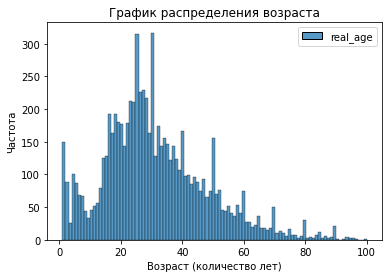

In [6]:
sns.histplot(
    data=df,
    bins=100
)
plt.xlabel('Возраст (количество лет)')
plt.ylabel('Частота')
plt.title('График распределения возраста');

Фотографии из датафрейма:

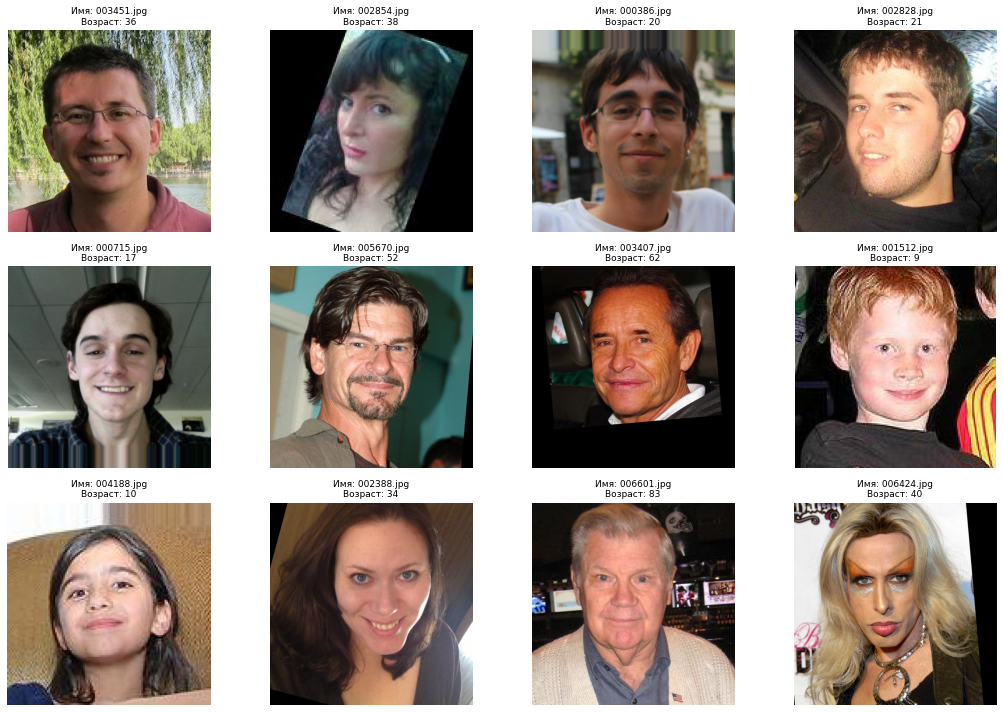

In [7]:
path_to_images = "/datasets/faces/final_files/"

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 10))

axes_flat = axes.flatten()

for i, ax in enumerate(axes_flat):
    
    random_row = df.sample(n=12).iloc[0]
    img_name = random_row["file_name"]
    age = random_row["real_age"] 

    img_path = os.path.join(path_to_images, img_name)
    img = Image.open(img_path)

    ax.imshow(img)
    
    ax.set_title(f"Имя: {img_name}\nВозраст: {age}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Промежуточные выводы:**

Предположительно, построенная модель будет обладать следующими характеристиками:
- **Высокая точность предсказания возраста молодых людей:** Модель будет идеально определять возраст в диапазоне 20–35 лет, потому что у неё огромный объём примеров для обучения в этой категории.
- **Проблемы с опредлением возраста пожилыми людьми:** Из-за нехватки данных (длинный «хвост» справа) нейросеть будет стабильно занижать возраст пожилых людей, пытаясь «притянуть» их к более частым классам.
- **Путаница из-за круглых чисел:** Из-за пиков на 30, 40 и 50 годах модель может переобучиться и выдавать эти «округленные» значения чаще, чем промежуточные 
- **Хорошая точность предсказания возраста детей:** Локальный пик в районе 1–5 лет — это плюс. Модель сможет накопить достаточно признаков, чтобы уверенно отличать совсем маленьких детей от подростков и взрослых.


# Обучение модели нейронной сети

Для решения задачи регрессии — определения возраста человека по фотографии — построим и обучим сверточную нейронную сеть на базе предобученной архитектуры **ResNet50**.

**Структура модели:**

1. **Подготовка генераторов данных:**
   * Разобьем исходный датасет на обучающую (75%) и валидационную (25%) выборки.
   * Нормализуем значения пикселей к диапазону $[0, 1]$.
   * Применим аугментацию (горизонтальное отражение `horizontal_flip`) исключительно к обучающей выборке для снижения риска переобучения.
   * Приведем входные изображения к единому разрешению $224 \times 224$ пикселя.

2. **Построение архитектуры:**
   * В качестве базовой основы (*backbone*) используем архитектуру **ResNet50**, предобученную на ImageNet, исключив исходные полносвязные слои (`include_top=False`).
   * Добавим слой глобального усредняющего пулинга (`GlobalAveragePooling2D`) для перехода к плоскому вектору признаков без взрывного роста числа параметров.
   * На выходе установим полносвязный слой с 1 нейроном и линейной функцией активации, соответствующей задаче регрессии.

3. **Компиляция и обучение:**
   * Оптимизатор: **Adam** с пониженным шагом обучения (`lr=0.0001`) для аккуратной донастройки предобученных весов.
   * Функция потерь: **MSE** (*Mean Squared Error*).
   * Целевая метрика качества: **MAE** (*Mean Absolute Error*).


Далее перешлем дполученный код на GPU-сервер.

In [1]:
def load_train(path):
    # Читаем CSV-файл из папки проекта
    labels = pd.read_csv(path + 'labels.csv')
    
    # Добавляем горизонтальное отражение для борьбы с переобучением
    datagen = ImageDataGenerator(
        validation_split=0.25,
        rescale=1.0 / 255,
        horizontal_flip=True
    )

    train_gen_flow = datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224), 
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=12345
    )

    return train_gen_flow


def load_test(path):
    labels = pd.read_csv(path + 'labels.csv')
    
    datagen = ImageDataGenerator(
        validation_split=0.25,
        rescale=1.0 / 255
    )

    test_gen_flow = datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=12345
    )

    return test_gen_flow


def create_model(input_shape=(224, 224, 3)):
    # Загружаем предобученный ResNet50
    backbone = ResNet50(
        weights='imagenet', 
        include_top=False, 
        input_shape=input_shape
    )
    
    backbone.trainable = True

    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(units=1, activation='linear'))

    optimizer = Adam(learning_rate=0.0001)

    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error',
        metrics=['mean_absolute_error']
    )

    return model


def train_model(
    model,
    train_data,
    test_data,
    batch_size=None,
    epochs=15,
    steps_per_epoch=None,
    validation_steps=None,
):
    if steps_per_epoch is None:
        steps_per_epoch = len(train_data)
    if validation_steps is None:
        validation_steps = len(test_data)

    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        verbose=2,
    )

    return model

```

Train for 178 steps, validate for 60 steps
Epoch 1/15
2026-09-03 16:23:31.222695: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcublas.so.10
2026-09-03 16:23:31.519005: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudnn.so.7
178/178 - 55s - loss: 224.8898 - mean_absolute_error: 10.7746 - val_loss: 798.0553 - val_mean_absolute_error: 23.3313
Epoch 2/15
178/178 - 38s - loss: 76.6391 - mean_absolute_error: 6.4802 - val_loss: 689.2253 - val_mean_absolute_error: 21.0985
Epoch 3/15
178/178 - 38s - loss: 49.0500 - mean_absolute_error: 5.2931 - val_loss: 232.7911 - val_mean_absolute_error: 11.4868
Epoch 4/15
178/178 - 38s - loss: 35.7199 - mean_absolute_error: 4.5826 - val_loss: 115.8529 - val_mean_absolute_error: 8.2917
Epoch 5/15
178/178 - 39s - loss: 27.3519 - mean_absolute_error: 3.9983 - val_loss: 74.5747 - val_mean_absolute_error: 6.5252
Epoch 6/15
178/178 - 38s - loss: 21.3135 - mean_absolute_error: 3.5080 - val_loss: 64.8478 - val_mean_absolute_error: 6.0266
Epoch 7/15
178/178 - 38s - loss: 17.2542 - mean_absolute_error: 3.1660 - val_loss: 71.6047 - val_mean_absolute_error: 6.1977
Epoch 8/15
178/178 - 39s - loss: 13.5199 - mean_absolute_error: 2.7968 - val_loss: 81.4153 - val_mean_absolute_error: 6.7687
Epoch 9/15
178/178 - 39s - loss: 11.9872 - mean_absolute_error: 2.6131 - val_loss: 61.9811 - val_mean_absolute_error: 5.9403
Epoch 10/15
178/178 - 38s - loss: 9.7529 - mean_absolute_error: 2.3695 - val_loss: 64.4954 - val_mean_absolute_error: 5.9448
Epoch 11/15
178/178 - 38s - loss: 9.3548 - mean_absolute_error: 2.3312 - val_loss: 61.8701 - val_mean_absolute_error: 5.8586
Epoch 12/15
178/178 - 38s - loss: 8.6915 - mean_absolute_error: 2.2411 - val_loss: 68.1085 - val_mean_absolute_error: 6.0971
Epoch 13/15
178/178 - 38s - loss: 8.2931 - mean_absolute_error: 2.1824 - val_loss: 69.8310 - val_mean_absolute_error: 6.1251
Epoch 14/15
178/178 - 38s - loss: 8.5530 - mean_absolute_error: 2.2045 - val_loss: 63.3311 - val_mean_absolute_error: 5.9150
Epoch 15/15
178/178 - 38s - loss: 8.1267 - mean_absolute_error: 2.1476 - val_loss: 66.6333 - val_mean_absolute_error: 6.0139
WARNING:tensorflow:sample_weight modes were coerced from
  ...
    to  
  ['...']
60/60 - 10s - loss: 66.6333 - mean_absolute_error: 6.0139
Test MAE: 6.0139

```

**Промежуточный вывод**

На тестовой выборке достигнуто значение MAE = 6.0139. В среднем модель ошибается в определении возраста человека по фотографии всего на 6 лет.

Модель обучалась в течение 15 эпох. Ошибка на валидации стремительно падала с 23.33 на первой эпохе до 5.85 к 11-й эпохе, после чего стабилизировалась в районе 5.9–6.0.

Разрыв между метрикой на обучении (MAE: 2.14) и валидации (Test MAE: 6.01) присутствует, однако применение аугментации позволило удержать модель от сильного переобучения и зафиксировать высокое качество на тесте.

# Выводы

Созданная модель помогает определять возраст покупателя с точностью +/- 6 лет разницы. В целом, для среднего и старшего возраста это приемлемо, учитывая, что бизнес хочет предлагать товары по интересам в зависимости от возраста. Однако, для платежспособной группы людей от 18-25 лет ошибка все же существенная - интересы по покупкам в этом возрасте могут сильно отличаться в возрастной группе 18 и возрастной группе 25 лет. Поэтому, модель можно дорабатывать в дальнейшем. Этого же касается запрос на продажу алкоголя.